# Chicago Taxi Trips, 11–17 September 2023

A descriptive summary of one week of **reported** taxi trips (Monday 2023-09-11 to Sunday 2023-09-17). All figures are reported trips, not total market volume.

## Summary

- **Demand (Q1):** Weekdays are steady at about 22,000 trips a day (Wednesday busiest at 22,694). Saturday is the quietest day at 12,719, and Sunday is close at 13,368. A weekend day averages 41% fewer trips than a weekday. Weekdays peak from 2 to 6 pm and have a smaller morning rush from 8 to 10 am. The quietest hours are 2 to 4 am, with fewer than 80 trips an hour on a weekday.
- **Pickups (Q2):** Three areas (76, 8 and 32) account for 60.5% of all trips, and the top 10 account for 85.1%. Area 76 has 23% of trips but 43% of revenue because its trips are much pricier (average `trip_total` $54.77 vs $29.76 overall). 2.8% of trips (3,815) have no pickup community area.
- **Payment and tips (Q3):** Credit cards carry 44% of trips and 60% of revenue. Cash is 30% of trips. Where tips are recorded (Credit Card and Mobile), they are 22.2% and 20.5% of fare. Cash tips are essentially unrecorded (0.4% of cash trips show one), so tipping can't be compared across payment types.
- **Companies (Q4):** Flash Cab and Taxi Affiliation Services each carry about 19% of trips. The top 10 companies carry 92% of trips. Taxicab Insurance Agency ranks third only after merging two spellings of its name.
- **Data quality:** All results are reported trips, not market volume. 626 trips (0.46%) are left out of money figures only, for missing, corrupt, zero or implausible amounts. No trip is dropped from counts. Section 2 lists every assumption.

## 1. Setup and data loading

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
pd.set_option('display.width', 160)

# Colours: validated categorical slots 1-2 (blue, orange); blue alone for single-series charts.
BLUE, ORANGE, GREY, INK, MUTED = '#2a78d6', '#eb6834', '#b9b8b2', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c9c8c2', 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#ebeae6', 'grid.linewidth': 0.8,
    'font.size': 10,
})
thousands = FuncFormatter(lambda v, _: f'{v:,.0f}')

raw = pd.read_csv('trips.csv', parse_dates=['trip_start_timestamp', 'trip_end_timestamp'])
print(f'{len(raw):,} rows x {raw.shape[1]} columns')
print('Start timestamps run from', raw.trip_start_timestamp.min(), 'to', raw.trip_start_timestamp.max())
print('trip_id unique:', raw.trip_id.is_unique)

135,768 rows x 23 columns
Start timestamps run from 2023-09-11 00:00:00 to 2023-09-17 23:45:00
trip_id unique: True


## 2. Data checks and cleaning

Principle: **every reported trip counts as a trip** (questions 1, 2 and 4 counts), but a trip only contributes to **money figures** (revenue, average fare, tip %) if its amounts look usable. Each rule below says how many rows it affects. Two tables on different bases are labelled as such.

### 2.1 Missing values

In [2]:
cols = ['trip_seconds','trip_end_timestamp','pickup_community_area','dropoff_community_area',
        'pickup_census_tract','fare','tips','tolls','extras','trip_total']
miss = raw[cols].isna().sum().to_frame('missing')
miss['% of rows'] = miss.missing / len(raw) * 100
miss

,missing,% of rows
trip_seconds,33,0.02
trip_end_timestamp,1,0.00
pickup_community_area,3815,2.81
dropoff_community_area,13794,10.16
pickup_census_tract,71404,52.59
fare,324,0.24
tips,324,0.24
tolls,324,0.24
extras,324,0.24
trip_total,324,0.24


- **Pickup community area** is missing for 3,815 trips. These are treated as "no pickup community area" (Q2). Per `dataset.md` this is mostly trips starting outside Chicago; I can't verify that without outside data.
- **Census tracts** are missing for about half of trips (suppression). Not used: geography uses community areas.
- **fare, tips, tolls, extras and trip_total are all missing together on the same 324 rows** (323 of them paid in cash). These trips stay in the counts but have no usable amounts.
- `trip_seconds` (33 rows) and `trip_end_timestamp` (1 row) are missing but no question uses them.

### 2.2 Company names

In [3]:
name_map = {
    'Taxicab Insurance Agency, LLC': 'Taxicab Insurance Agency Llc',   # punctuation variant
    'Choice Taxi Association Inc':   'Choice Taxi Association',        # suffix variant
}
raw['company_std'] = raw.company.replace(name_map)

before = raw.company.value_counts().head(12).rename('trips (raw names)')
after = raw.company_std.value_counts().head(12).rename('trips (standardised)')
print('Companies before:', raw.company.nunique(), '| after:', raw.company_std.nunique())
for a, b in name_map.items():
    shared = len(set(raw.loc[raw.company==a,'taxi_id']) & set(raw.loc[raw.company==b,'taxi_id']))
    print(f'  {a!r} -> {b!r}: {(raw.company==a).sum():,} trips relabelled; taxis shared by both names: {shared}')
pd.concat([before.reset_index().rename(columns={'company':'raw name'}),
           after.reset_index().rename(columns={'company_std':'standardised name'})], axis=1)

Companies before: 32 | after: 30
  'Taxicab Insurance Agency, LLC' -> 'Taxicab Insurance Agency Llc': 2,379 trips relabelled; taxis shared by both names: 0
  'Choice Taxi Association Inc' -> 'Choice Taxi Association': 1,064 trips relabelled; taxis shared by both names: 0


,raw name,trips (raw names),standardised name,trips (standardised)
0,Flash Cab,25950,Flash Cab,25950
1,Taxi Affiliation Services,25727,Taxi Affiliation Services,25727
2,Sun Taxi,15122,Taxicab Insurance Agency Llc,16293
3,Taxicab Insurance Agency Llc,13914,Sun Taxi,15122
4,City Service,13747,City Service,13747
5,Chicago Independents,8004,Chicago Independents,8004
6,5 Star Taxi,6121,5 Star Taxi,6121
7,Medallion Leasin,5003,Medallion Leasin,5003
8,Globe Taxi,4772,Globe Taxi,4772
9,Blue Ribbon Taxi Association,4390,Blue Ribbon Taxi Association,4390


Two companies appear under two spellings each, and no taxi appears under both spellings of a pair. I merged them as the same company (**13,914 + 2,379 trips and 2,022 + 1,064 trips**). This matters for the ranking: without the merge, Taxicab Insurance Agency would rank 4th (13,914 trips) behind Sun Taxi instead of 3rd (16,293). The top-10 membership itself does not change. The raw name `Taxi Affiliation Services Llc - Yell...` (75 trips) is probably a Taxi Affiliation Services brand, but I can't confirm, so I left it separate. It doesn't affect the top 10.

### 2.3 Does `trip_total` match the sum of its parts?

In [4]:
amt = raw[raw.fare.notna()].copy()
amt['residual'] = (amt.trip_total - (amt.fare + amt.tips + amt.tolls + amt.extras)).round(2)
amt['residual_group'] = np.select(
    [amt.residual == 0, amt.residual == 0.5, amt.residual > 0.5],
    ['exact match', 'trip_total is $0.50 higher', 'trip_total is $1.00 to $3.00 higher'], 'trip_total is lower')
tab = pd.crosstab(amt.payment_type, amt.residual_group, margins=True)
display(tab)
print('Residual values:', amt.residual.value_counts().sort_index().to_dict())
print('Smallest / largest residual:', amt.residual.min() + 0.0, '/', amt.residual.max())

residual_group,exact match,trip_total is $0.50 higher,trip_total is $1.00 to $3.00 higher,All
payment_type,,,,
Cash,39052,3,675,39730
Credit Card,16962,42409,919,60290
Dispute,31,0,0,31
Mobile,14420,4110,64,18594
No Charge,54,0,0,54
Prcard,11944,0,17,11961
Unknown,4784,0,0,4784
All,87247,46522,1675,135444


Residual values: {0.0: 87247, 0.5: 46522, 1.0: 109, 1.5: 4, 1.95: 5, 2.0: 2, 2.5: 751, 3.0: 804}
Smallest / largest residual: 0.0 / 3.0


`trip_total` is **never lower** than fare + tips + tolls + extras and is never more than $3.00 higher. The gap is not random:

- **$0.50 gaps (46,522 trips)** sit almost entirely on Credit Card and Mobile trips. Cash, Prcard and Unknown almost never show it. My inference is a per-trip charge on those payment types that has no column of its own. This is an inference, not documented.
- **$1.00 to $3.00 gaps (1,675 trips)** look like other unlisted fees. I can't identify them.

**Decision:** keep `trip_total` as the reported revenue figure and exclude nothing for these gaps, because they're small and one-directional. Revenue is "as reported in `trip_total`", which includes these fees. Tip % uses `fare` as the base, as the brief asks.

### 2.4 Implausible amounts, distances and durations

In [5]:
fare_per_mile = raw.fare / raw.trip_miles.replace(0, np.nan)

raw['f_missing'] = raw.fare.isna()
raw['f_corrupt'] = (raw.trip_total > 1000) | (raw.tolls >= 1000) | (raw.extras >= 1000)
raw['f_zero_total'] = raw.trip_total.eq(0)
raw['f_implausible_fare'] = (raw.fare > 100) & ((raw.trip_miles < 1) | (fare_per_mile > 10)) & ~raw.f_corrupt

# Money flags are mutually exclusive in this report, in priority order, so rows are counted once.
raw['money_reason'] = np.select(
    [raw.f_missing, raw.f_corrupt, raw.f_zero_total, raw.f_implausible_fare],
    ['amounts missing', 'corrupt amount (placeholder tolls/extras)', 'trip_total is zero', 'fare > $100 on a <1 mile or >$10/mile trip'],
    default='ok')
raw['money_ok'] = raw.money_reason.eq('ok')

summary = (raw[~raw.money_ok].groupby('money_reason')
           .agg(rows=('trip_id','size'), trip_total_reported=('trip_total','sum')))
summary.loc['TOTAL excluded from money figures'] = [summary.rows.sum(), summary.trip_total_reported.sum()]
summary['% of all trips'] = summary.rows / len(raw) * 100
display(summary)
print(f"Trips used in money figures: {raw.money_ok.sum():,} of {len(raw):,}; "
      f"trip_total on those: ${raw.loc[raw.money_ok,'trip_total'].sum():,.0f}")

print()
print('Top corrupt rows (tolls/extras of 4,111 or 4,444 are placeholder-looking values):')
display(raw.loc[raw.f_corrupt, ['trip_miles','trip_seconds','fare','tolls','extras','trip_total','payment_type']])

,rows,trip_total_reported,% of all trips
money_reason,,,
amounts missing,324,0.00,0.24
corrupt amount (placeholder tolls/extras),3,"21,911.55",0.00
fare > $100 on a <1 mile or >$10/mile trip,165,"35,234.06",0.12
trip_total is zero,134,0.00,0.10
TOTAL excluded from money figures,626,"57,145.61",0.46


Trips used in money figures: 135,142 of 135,768; trip_total on those: $4,022,203

Top corrupt rows (tolls/extras of 4,111 or 4,444 are placeholder-looking values):


,trip_miles,trip_seconds,fare,tolls,extras,trip_total,payment_type
25636,0.00,0.00,3.25,"4,444.44","4,444.44","8,892.13",Cash
35524,1.30,420.00,6.75,"4,111.10",0.44,"4,118.29",Cash
124235,0.10,"1,080.00",11.25,"4,444.44","4,445.44","8,901.13",Cash


- **Corrupt amounts (3 rows):** tolls/extras of $4,111 to $4,444 on trips of 0 to 1 miles, giving totals up to $8,901. These are obvious data errors. Together they carry $21,900 of reported `trip_total`, about 0.5% of the valid total.
- **Zero `trip_total` (134 rows, not already excluded):** a trip with no amount at all can't contribute to average fare or tip %, so these are excluded from money figures.
- **Implausible fares (165 rows):** fares over $100 on trips under 1 mile or above $10 per mile (for example $400 for 10 seconds). Genuine long trips such as 195 miles for $445 are *not* caught. This is a judgement call: these might be flat or pre-agreed fares with the meter off, but they cannot be verified. Their reported `trip_total` is about $35,000, 0.9% of revenue, so the choice is small either way.
- **Cut-offs are rules of thumb, not documented thresholds.** The $1,000 and $100 / $10-per-mile cut-offs are mine.

In [6]:
dist = pd.DataFrame({
    'trips': [
        ((raw.trip_miles == 0)).sum(),
        ((raw.trip_seconds == 0)).sum(),
        ((raw.trip_miles == 0) & (raw.trip_seconds == 0)).sum(),
        ((raw.trip_miles > 50)).sum(),
        ((raw.trip_seconds > 4*3600)).sum(),
        ((raw.trip_miles / (raw.trip_seconds/3600)) > 80).sum(),
    ]}, index=['zero miles', 'zero seconds', 'zero miles AND zero seconds',
               'more than 50 miles', 'longer than 4 hours', 'average speed above 80 mph'])
dist['% of all trips'] = dist.trips / len(raw) * 100
dist

,trips,% of all trips
zero miles,13993,10.31
zero seconds,2731,2.01
zero miles AND zero seconds,2637,1.94
more than 50 miles,75,0.06
longer than 4 hours,121,0.09
average speed above 80 mph,228,0.17


**Distance and duration are not used in any of the four questions, so I did not exclude any row for them.** They are shown here so the reader knows they exist. Many zero-mile trips carry a normal fare, so they look like very short trips, not errors. The 2,637 trips with both zero miles and zero seconds are mostly (about 70%) a bare $3.25 base fare, which looks like a meter started and cancelled. They are kept as trips because the records are reported. The sensitivity check below shows what happens if they are dropped.

**Duplicates:** 92 rows are exact copies of another row in every column except `trip_id` (82% of them zero-length $3.25 trips). Since `trip_id` is unique, I treated them as separate trips and removed none.

### 2.5 Derived fields and sensitivity check

In [7]:
df = raw.copy()
df['date'] = df.trip_start_timestamp.dt.date
df['dow'] = df.trip_start_timestamp.dt.day_of_week                   # 0 = Monday
df['day_name'] = df.trip_start_timestamp.dt.day_name()
df['hour'] = df.trip_start_timestamp.dt.hour
df['weekend'] = df.dow >= 5
df['null_trip'] = (df.trip_miles == 0) & (df.trip_seconds == 0)
df['pickup_area'] = df.pickup_community_area.astype('Int64').astype('string').fillna('none')
money = df[df.money_ok]            # base for every money figure

print(f'All reported trips (counts): {len(df):,}')
print(f'Valid-amount trips (money):  {len(money):,}  ({len(money)/len(df):.1%})')

# Sensitivity: rerun headline results on a strict set that also drops zero-length trips.
strict = df[df.money_ok & ~df.null_trip]
print(f'Strict set: {len(strict):,} trips (drops {len(df)-len(strict):,})')
sens = pd.DataFrame({
    'busiest day': [df.day_name.value_counts().idxmax(), strict.day_name.value_counts().idxmax()],
    'quietest day': [df.day_name.value_counts().idxmin(), strict.day_name.value_counts().idxmin()],
    'busiest hour': [df.hour.value_counts().idxmax(), strict.hour.value_counts().idxmax()],
    'top-10 pickup areas shared': [10, len(set(df.pickup_community_area.value_counts().head(10).index) & set(strict.pickup_community_area.value_counts().head(10).index))],
    'top-10 companies shared': [10, len(set(df.company_std.value_counts().head(10).index) & set(strict.company_std.value_counts().head(10).index))],
}, index=['all trips', 'strict set'])
sens

All reported trips (counts): 135,768
Valid-amount trips (money):  135,142  (99.5%)
Strict set: 132,585 trips (drops 3,183)


,busiest day,quietest day,busiest hour,top-10 pickup areas shared,top-10 companies shared
all trips,Wednesday,Saturday,17,10,10
strict set,Wednesday,Saturday,17,10,10


The headline results do not change on the strict set, so the choice to keep zero-length trips in the counts doesn't drive any conclusion.

### 2.6 Assumptions and exclusions at a glance

| # | Decision | Rows affected |
|---|---|---|
| 1 | Trip counts (Q1, Q2 counts, Q4 counts and shares) use **all** reported trips | 135,768 |
| 2 | Money figures (revenue, average fare, tip %) exclude trips with missing amounts | 324 |
| 3 | …and exclude corrupt placeholder amounts | 3 |
| 4 | …and exclude trips with `trip_total` = 0 | 134 |
| 5 | …and exclude fare > $100 on a <1 mile or >$10/mile trip | 165 |
| 6 | Two pairs of company spellings merged | 3,443 trips relabelled: 2,379 + 1,064 (see 2.2) |
| 7 | `trip_total` is kept as reported even where it exceeds the sum of parts by up to $3.00 | 48,197 trips show a gap; none excluded |
| 8 | Distance and duration oddities are reported but not excluded (not used) | see 2.4 |
| 9 | Exact duplicates apart from `trip_id` are kept | 92 |
| 10 | Trips with no pickup community area are kept in counts and shown as "none" | 3,815 |
| 11 | Hour and day are taken from `trip_start_timestamp`, which is rounded to 15 minutes. A trip starting at 23:53 is recorded as 00:00 of the next day, so rounding moves a few trips across hour and day boundaries | all |
| 12 | The week contains each weekday once. "Weekday" means Mon–Fri and "weekend" Sat–Sun. No holiday falls in the week | all |

## 3. When is demand highest?

Trip counts by day of week and hour of trip start, all reported trips.

In [8]:
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
by_day = df.groupby('day_name').size().reindex(order).to_frame('trips')
by_day['% of week'] = by_day.trips / by_day.trips.sum() * 100
by_day['vs weekday average'] = by_day.trips / by_day.trips.iloc[:5].mean() - 1
display(by_day.style.format({'trips':'{:,.0f}', '% of week':'{:.1f}%', 'vs weekday average':'{:+.0%}'}))

wk = df.groupby('weekend').size()
print(f"Average per weekday: {wk[False]/5:,.0f} trips | average per weekend day: {wk[True]/2:,.0f} trips "
      f"({wk[True]/2 / (wk[False]/5) - 1:+.0%})")

,trips,% of week,vs weekday average
day_name,,,
Monday,"22,190",16.3%,+1%
Tuesday,"22,040",16.2%,+0%
Wednesday,"22,694",16.7%,+3%
Thursday,"22,531",16.6%,+3%
Friday,"20,226",14.9%,-8%
Saturday,"12,719",9.4%,-42%
Sunday,"13,368",9.8%,-39%


Average per weekday: 21,936 trips | average per weekend day: 13,044 trips (-41%)


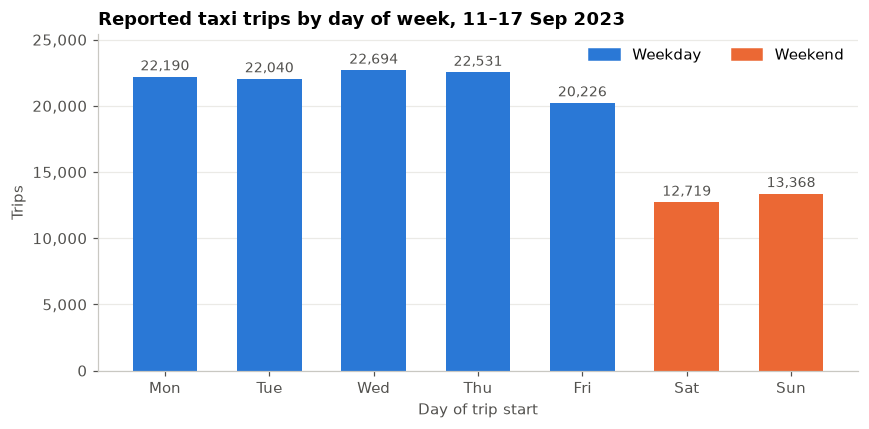

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = [BLUE]*5 + [ORANGE]*2
bars = ax.bar(by_day.index.str[:3], by_day.trips, color=colors, width=0.62)
for b, v in zip(bars, by_day.trips):
    ax.text(b.get_x()+b.get_width()/2, v+250, f'{v:,.0f}', ha='center', va='bottom', color=MUTED, fontsize=9)
ax.set_title('Reported taxi trips by day of week, 11–17 Sep 2023')
ax.set_xlabel('Day of trip start'); ax.set_ylabel('Trips')
ax.yaxis.set_major_formatter(thousands); ax.set_ylim(0, by_day.trips.max()*1.12); ax.grid(axis='x', visible=False)
ax.legend(handles=[plt.Rectangle((0,0),1,1,color=BLUE), plt.Rectangle((0,0),1,1,color=ORANGE)],
          labels=['Weekday','Weekend'], frameon=False, loc='upper right', ncol=2)
plt.tight_layout(); plt.show()

,trips,% of week,weekday (avg per day),weekend (avg per day)
hour,,,,
0,"2,406",1.8%,335,366
1,"1,423",1.0%,169,290
2,772,0.6%,75,198
3,632,0.5%,76,127
4,867,0.6%,120,133
5,"1,357",1.0%,220,129
6,"2,594",1.9%,437,204
7,"4,614",3.4%,818,262
8,"6,619",4.9%,"1,163",402


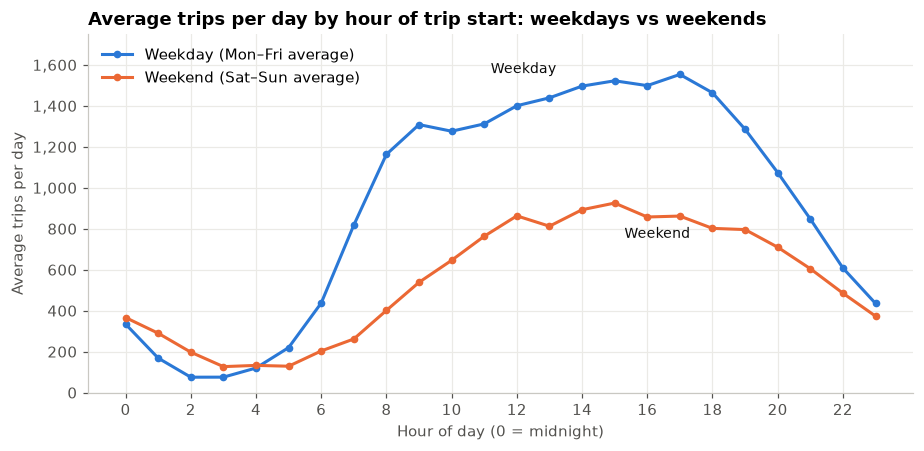

In [10]:
hourly = df.groupby('hour').size().to_frame('trips')
hourly['% of week'] = hourly.trips / hourly.trips.sum() * 100
prof = pd.DataFrame({
    'weekday (avg per day)': df[~df.weekend].groupby('hour').size() / 5,
    'weekend (avg per day)': df[df.weekend].groupby('hour').size() / 2,
})
tbl = hourly.join(prof)
display(tbl.style.format({'trips':'{:,.0f}','% of week':'{:.1f}%','weekday (avg per day)':'{:,.0f}','weekend (avg per day)':'{:,.0f}'}))

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(prof.index, prof.iloc[:,0], color=BLUE, lw=2, marker='o', ms=4, label='Weekday (Mon–Fri average)')
ax.plot(prof.index, prof.iloc[:,1], color=ORANGE, lw=2, marker='o', ms=4, label='Weekend (Sat–Sun average)')
ax.text(11.2, 1560, 'Weekday', color=INK, fontsize=9, ha='left')
ax.text(15.3, prof.iloc[15,1]-170, 'Weekend', color=INK, fontsize=9, ha='left')
ax.set_title('Average trips per day by hour of trip start: weekdays vs weekends')
ax.set_xlabel('Hour of day (0 = midnight)'); ax.set_ylabel('Average trips per day')
ax.set_xticks(range(0,24,2)); ax.yaxis.set_major_formatter(thousands); ax.set_ylim(0, 1750)
ax.legend(frameon=False, loc='upper left'); plt.tight_layout(); plt.show()

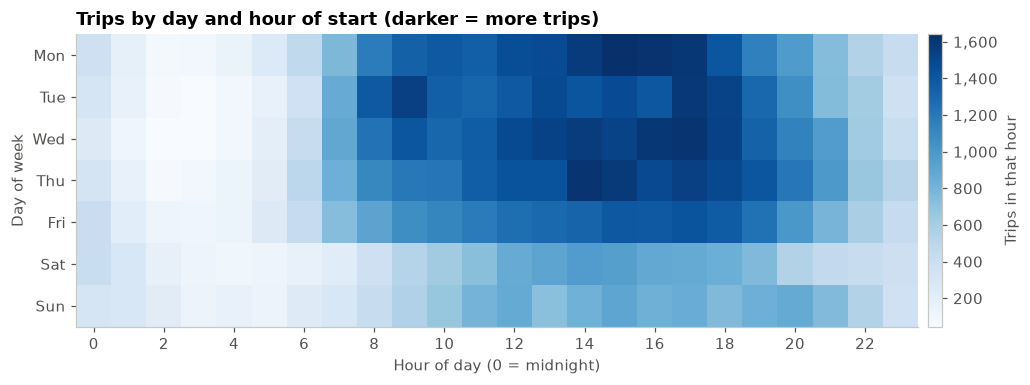

Busiest 5 day-hours:


,day_name,hour,trips
0,Monday,15,1642
1,Monday,16,1619
2,Wednesday,17,1615
3,Thursday,14,1611
4,Monday,17,1597


Quietest 5 day-hours:


,day_name,hour,trips
0,Wednesday,3,45
1,Tuesday,3,46
2,Wednesday,2,51
3,Thursday,2,61
4,Tuesday,2,63


In [11]:
heat = pd.crosstab(df.day_name, df.hour).reindex(order)
fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(heat.values, aspect='auto', cmap='Blues')
ax.set_xticks(range(0,24,2)); ax.set_xticklabels(range(0,24,2))
ax.set_yticks(range(7)); ax.set_yticklabels([d[:3] for d in order]); ax.grid(False)
ax.set_title('Trips by day and hour of start (darker = more trips)')
ax.set_xlabel('Hour of day (0 = midnight)'); ax.set_ylabel('Day of week')
cb = fig.colorbar(im, ax=ax, pad=0.01); cb.set_label('Trips in that hour'); cb.ax.yaxis.set_major_formatter(thousands)
plt.tight_layout(); plt.show()

cells = heat.stack().rename('trips').reset_index().rename(columns={'level_1':'hour'})
cells['hour'] = cells['hour'].astype(int)
print('Busiest 5 day-hours:'); display(cells.nlargest(5,'trips').reset_index(drop=True))
print('Quietest 5 day-hours:'); display(cells.nsmallest(5,'trips').reset_index(drop=True))

**Takeaway.** The week's demand is steady on weekdays and about 40% lower on weekends. Monday to Thursday run at 22,000 to 22,700 trips a day, Friday drops to 20,226, Saturday is the quietest day at 12,719 and Sunday is close at 13,368. Weekdays follow a commuter-style shape: a morning climb from 6 am, a plateau of roughly 1,300 to 1,550 trips an hour from 9 am, and a peak between 2 and 6 pm (about 1,500 an hour). The single busiest hours are Monday 3 pm (1,642 trips) and Monday 4 pm (1,619). The quietest period is 2 to 4 am midweek, where Tuesday and Wednesday at 3 am have only 45 to 46 trips in the whole hour. Weekends are flatter, build slowly and peak at about 900 an hour in the afternoon, but are *busier than weekdays* from midnight to 4 am (for example 290 vs 169 an hour at 1 am).

## 4. Where do trips start?

Pickup community areas are shown by number, because area names are outside data and out of scope. "Trips" counts all reported trips; "trip_total" uses valid-amount trips only (section 2).

In [12]:
n_all = len(df)
pa = df.pickup_community_area
none_n = pa.isna().sum()
print(f'Trips with no pickup community area: {none_n:,} of {n_all:,} = {none_n/n_all:.2%}')
print(f'  ...of which also have no pickup centroid (so probably outside the area): {(pa.isna() & df.pickup_centroid_latitude.isna()).sum():,}')

by_area = df.groupby('pickup_area').agg(trips=('trip_id','size'))
by_area['trip_total'] = money.groupby('pickup_area').trip_total.sum()
by_area['trip_total'] = by_area.trip_total.fillna(0)
by_area['% of trips'] = by_area.trips / n_all * 100
by_area['% of trip_total'] = by_area.trip_total / money.trip_total.sum() * 100
known = by_area.drop(index='none')

top_trips = known.nlargest(10, 'trips'); top_rev = known.nlargest(10, 'trip_total')
fmt = {'trips':'{:,.0f}','trip_total':'${:,.0f}','% of trips':'{:.1f}%','% of trip_total':'{:.1f}%'}
print('Top 10 pickup community areas by trip count'); display(top_trips.style.format(fmt))
print('Top 10 pickup community areas by total trip_total'); display(top_rev.style.format(fmt))
print('Top-10 lists share', len(set(top_trips.index) & set(top_rev.index)), 'areas;',
      f'top 10 by count cover {top_trips.trips.sum()/n_all:.1%} of all trips;',
      f'top 3 cover {top_trips.trips.head(3).sum()/n_all:.1%}')

Trips with no pickup community area: 3,815 of 135,768 = 2.81%
  ...of which also have no pickup centroid (so probably outside the area): 3,775
Top 10 pickup community areas by trip count


,trips,trip_total,% of trips,% of trip_total
pickup_area,,,,
76,"31,659","$1,727,204",23.3%,42.9%
8,"28,315","$516,187",20.9%,12.8%
32,"22,138","$419,668",16.3%,10.4%
28,"11,298","$184,404",8.3%,4.6%
33,"6,701","$171,967",4.9%,4.3%
56,"5,427","$251,207",4.0%,6.2%
6,"3,941","$77,709",2.9%,1.9%
7,"2,543","$48,602",1.9%,1.2%
3,"1,920","$39,354",1.4%,1.0%


Top 10 pickup community areas by total trip_total


,trips,trip_total,% of trips,% of trip_total
pickup_area,,,,
76,"31,659","$1,727,204",23.3%,42.9%
8,"28,315","$516,187",20.9%,12.8%
32,"22,138","$419,668",16.3%,10.4%
56,"5,427","$251,207",4.0%,6.2%
28,"11,298","$184,404",8.3%,4.6%
33,"6,701","$171,967",4.9%,4.3%
6,"3,941","$77,709",2.9%,1.9%
7,"2,543","$48,602",1.9%,1.2%
3,"1,920","$39,354",1.4%,1.0%


Top-10 lists share 10 areas; top 10 by count cover 85.1% of all trips; top 3 cover 60.5%


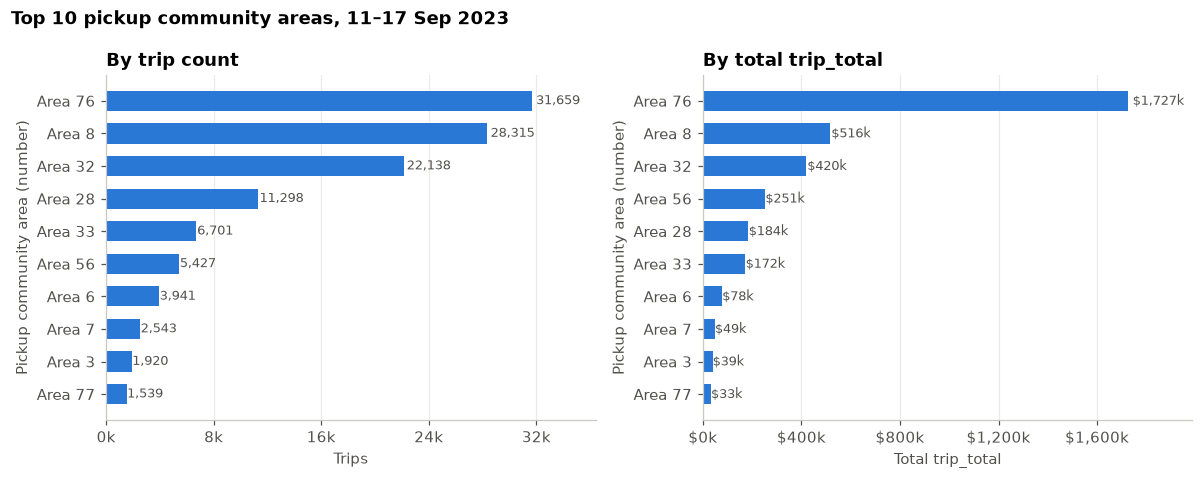

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, t, col, title, xl, fmtf in [
    (axes[0], top_trips, 'trips', 'By trip count', 'Trips', lambda v: f'{v:,.0f}'),
    (axes[1], top_rev, 'trip_total', 'By total trip_total', 'Total trip_total', lambda v: f'${v/1000:,.0f}k')]:
    t = t.iloc[::-1]
    ax.barh('Area ' + t.index, t[col], color=BLUE, height=0.62)
    for y, v in enumerate(t[col]):
        ax.text(v*1.01, y, fmtf(v), va='center', color=MUTED, fontsize=8.5)
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel('Pickup community area (number)')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _, pre=('' if col == 'trips' else '$'): f'{pre}{v/1000:,.0f}k')); ax.xaxis.set_major_locator(MaxNLocator(5)); ax.grid(axis='y', visible=False)
    ax.set_xlim(0, t[col].max()*1.15)
fig.suptitle('Top 10 pickup community areas, 11–17 Sep 2023', x=0.01, ha='left', fontweight='bold', fontsize=12)
plt.tight_layout(); plt.show()

**Takeaway.** Pickups are heavily concentrated: areas 76, 8 and 32 produce 60.5% of all reported trips (23.3%, 20.9% and 16.3%) and the top 10 areas produce 85.1%. The same ten areas appear in both top-10 lists, but the order changes by revenue. Area 76 is first on both lists, but its share jumps from 23% of trips to 43% of `trip_total` ($1.73m), because its average trip is worth $54.77 against $18.30 for area 8 and $29.76 overall. Area 56 moves from 6th by trips to 4th by revenue and area 28 drops from 4th to 5th, which suggests area 56's trips are longer or pricier. 3,815 trips (2.81%) have no pickup community area; 3,775 of them also lack any pickup location, consistent with trips starting outside Chicago, though that can't be confirmed from this file.

## 5. How do riders pay and tip?

Trips and share use all reported trips. Revenue (`trip_total`), average fare and tip % use valid-amount trips only. **Tip % = total tips ÷ total fare** for the group (a ratio of sums), not the average of per-trip percentages, because a few tiny fares with large tips would distort the latter. "% with tip" is the share of trips whose tip is above zero.

In [14]:
g_all = df.groupby('payment_type').size().rename('trips')
g = money.groupby('payment_type').agg(valid_trips=('trip_id','size'), revenue=('trip_total','sum'),
                                      avg_fare=('fare','mean'), fare_sum=('fare','sum'), tips_sum=('tips','sum'),
                                      with_tip=('tips', lambda s: (s > 0).mean()*100))
pay = pd.concat([g_all, g], axis=1).sort_values('trips', ascending=False)
pay['% of trips'] = pay.trips / pay.trips.sum() * 100
pay['tip % of fare'] = pay.tips_sum / pay.fare_sum * 100
pay = pay.rename(columns={'avg_fare':'average fare ($)', 'revenue':'revenue ($)', 'with_tip':'% of trips with a tip', 'valid_trips':'trips with valid amounts'})
pay_view = pay[['trips','% of trips','trips with valid amounts','revenue ($)','average fare ($)','tip % of fare','% of trips with a tip']]
# Tip columns are deliberately blank for the total row: pooling cash (tips unrecorded) with card payments is not like-for-like.
pay_view.loc['All types'] = [pay.trips.sum(), 100.0, pay['trips with valid amounts'].sum(), pay['revenue ($)'].sum(),
                             money.fare.mean(), np.nan, np.nan]
display(pay_view.style.format({'trips':'{:,.0f}','% of trips':'{:.1f}%','trips with valid amounts':'{:,.0f}','revenue ($)':'${:,.0f}',
                               'average fare ($)':'${:.2f}','tip % of fare':'{:.1f}%','% of trips with a tip':'{:.1f}%'}, na_rep='—'))

,trips,% of trips,trips with valid amounts,revenue ($),average fare ($),tip % of fare,% of trips with a tip
payment_type,,,,,,,
Credit Card,"60,291",44.4%,"60,161","$2,396,522",$28.74,22.2%,93.6%
Cash,"40,053",29.5%,"39,561","$785,728",$18.19,0.1%,0.4%
Mobile,"18,594",13.7%,"18,594","$413,943",$17.81,20.5%,92.7%
Prcard,"11,961",8.8%,"11,961","$307,514",$25.43,0.7%,5.2%
Unknown,"4,784",3.5%,"4,783","$115,614",$24.04,0.0%,0.1%
No Charge,54,0.0%,51,"$2,131",$34.98,1.9%,7.8%
Dispute,31,0.0%,31,$752,$21.31,0.0%,0.0%
All types,"135,768",100.0%,"135,142","$4,022,203",$23.69,—,—


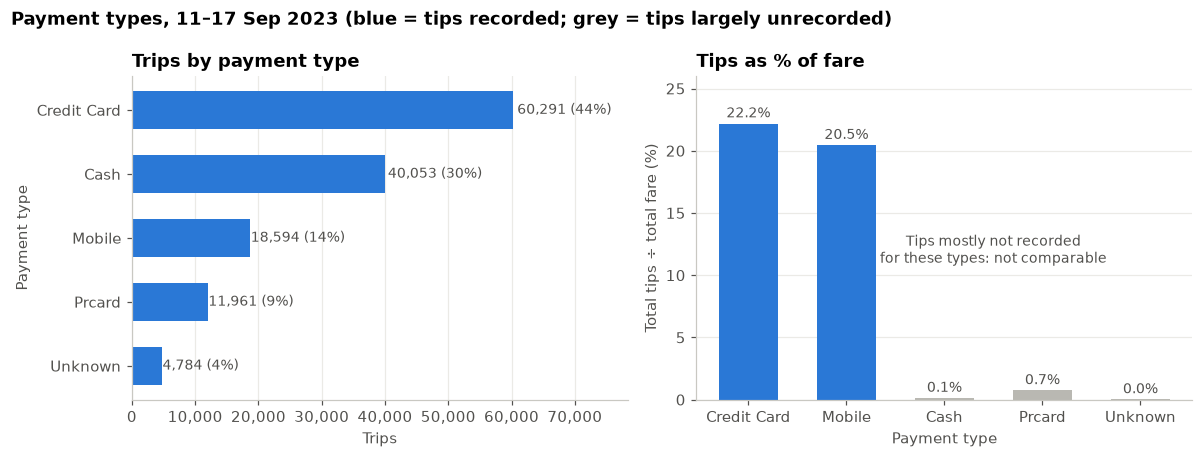

Median tip % of fare among Credit Card / Mobile trips with a tip: {'Credit Card': 23.0, 'Mobile': 22.8}
Card + Mobile combined tip % of fare: 21.9


In [15]:
main = pay.drop(index=['Dispute','No Charge'])             # the two tiny types stay in the table only
like = ['Credit Card','Mobile']

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
m_ = main.iloc[::-1]
ax.barh(m_.index, m_.trips, color=BLUE, height=0.6)
for y, (v, p) in enumerate(zip(m_.trips, m_['% of trips'])):
    ax.text(v*1.01, y, f'{v:,.0f} ({p:.0f}%)', va='center', color=MUTED, fontsize=9)
ax.set_title('Trips by payment type'); ax.set_xlabel('Trips'); ax.set_ylabel('Payment type')
ax.xaxis.set_major_formatter(thousands); ax.set_xlim(0, m_.trips.max()*1.3); ax.grid(axis='y', visible=False)

ax = axes[1]
m2 = main.loc[like + [t for t in main.index if t not in like]]
cols_ = [BLUE if t in like else GREY for t in m2.index]
bars = ax.bar(m2.index, m2['tip % of fare'], color=cols_, width=0.6)
for b, v, t in zip(bars, m2['tip % of fare'], m2.index):
    ax.text(b.get_x()+b.get_width()/2, v+0.5, f'{v:.1f}%', ha='center', color=MUTED, fontsize=9)
ax.text(2.5, 11, 'Tips mostly not recorded\nfor these types: not comparable', ha='center', color=MUTED, fontsize=9)
ax.set_title('Tips as % of fare'); ax.set_xlabel('Payment type'); ax.set_ylabel('Total tips ÷ total fare (%)')
ax.set_ylim(0, 26); ax.grid(axis='x', visible=False)
fig.suptitle('Payment types, 11–17 Sep 2023 (blue = tips recorded; grey = tips largely unrecorded)', x=0.01, ha='left', fontweight='bold', fontsize=12)
plt.tight_layout(); plt.show()

cc = money[money.payment_type.isin(like)]
print('Median tip % of fare among Credit Card / Mobile trips with a tip:',
      (cc[cc.tips>0].tips / cc[cc.tips>0].fare * 100).groupby(cc[cc.tips>0].payment_type).median().round(1).to_dict())
print('Card + Mobile combined tip % of fare:', round(cc.tips.sum()/cc.fare.sum()*100, 1))

**Takeaway.** Credit Card is the main payment type: 60,291 trips (44.4%) and $2.40m of revenue (60%) with the highest average fare ($28.74). Cash is second with 40,053 trips (29.5%) but a lower average fare ($18.19) and $0.79m revenue. Mobile (13.7%) has the lowest average fare ($17.81), which suggests shorter or cheaper trips (I haven't checked trip length). Prcard is 8.8% and Unknown 3.5%. Tips are only comparable for Credit Card (22.2% of fare, tip on 93.6% of trips) and Mobile (20.5%, 92.7%); the typical tip among tippers is about 23% for both. Cash (0.13%), Prcard (0.74%) and Unknown (0.02%) show almost no tips, which reflects unrecorded tips, not stingy riders, so these figures say nothing about how generously those riders tip. The 'All types' row deliberately has no tip figure.

## 6. Which companies carry the trips?

Company names are standardised as in section 2.2. Trips, share and distinct taxis use all reported trips. Revenue (`trip_total`) uses valid-amount trips.

In [16]:
co = df.groupby('company_std').agg(trips=('trip_id','size'), taxis=('taxi_id','nunique'))
co['revenue ($)'] = money.groupby('company_std').trip_total.sum()
co['% of all trips'] = co.trips / len(df) * 100
co = co.sort_values('trips', ascending=False)
top_co = co.head(10).copy()
top_co.index.name = 'company'
top_co = top_co[['trips','revenue ($)','% of all trips','taxis']].rename(columns={'taxis':'distinct taxis'})
display(top_co.style.format({'trips':'{:,.0f}','revenue ($)':'${:,.0f}','% of all trips':'{:.1f}%','distinct taxis':'{:,.0f}'}))
print(f"Top 10 together: {top_co.trips.sum():,} trips = {top_co.trips.sum()/len(df):.1%} of all trips; "
      f"{co.shape[0]} companies in total; {df.taxi_id.nunique():,} distinct taxis overall.")
print('Taxis reported under more than one company:', int((df.groupby('taxi_id').company_std.nunique() > 1).sum()),
      '(counted once under each company; the overall distinct count above counts each taxi once)')

,trips,revenue ($),% of all trips,distinct taxis
company,,,,
Flash Cab,"25,950","$683,254",19.1%,401
Taxi Affiliation Services,"25,727","$721,597",18.9%,457
Taxicab Insurance Agency Llc,"16,293","$524,692",12.0%,356
Sun Taxi,"15,122","$482,019",11.1%,299
City Service,"13,747","$420,222",10.1%,265
Chicago Independents,"8,004","$254,552",5.9%,189
5 Star Taxi,"6,121","$206,288",4.5%,140
Medallion Leasin,"5,003","$152,948",3.7%,98
Globe Taxi,"4,772","$140,935",3.5%,104


Top 10 together: 125,129 trips = 92.2% of all trips; 30 companies in total; 2,656 distinct taxis overall.
Taxis reported under more than one company: 3 (counted once under each company; the overall distinct count above counts each taxi once)


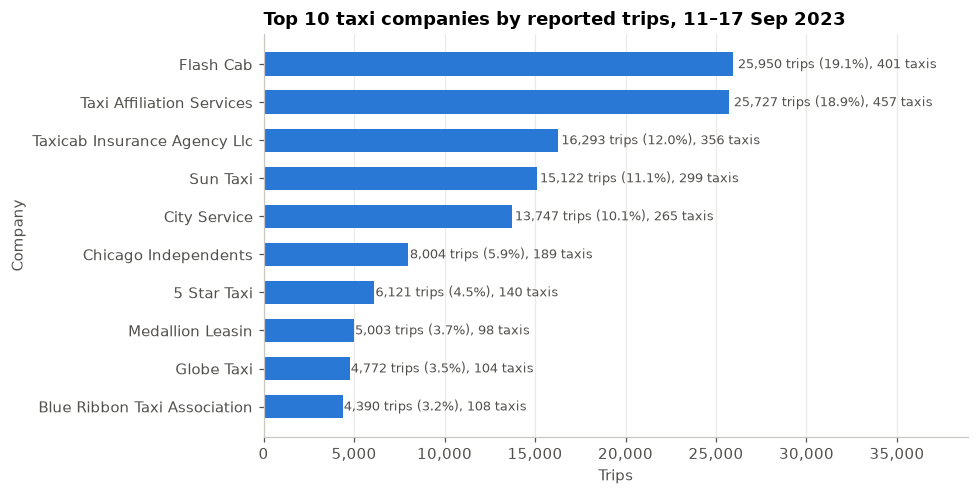

In [17]:
t = top_co.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(t.index, t.trips, color=BLUE, height=0.62)
for y, (v, p, k) in enumerate(zip(t.trips, t['% of all trips'], t['distinct taxis'])):
    ax.text(v*1.01, y, f'{v:,.0f} trips ({p:.1f}%), {k:,.0f} taxis', va='center', color=MUTED, fontsize=8.5)
ax.set_title('Top 10 taxi companies by reported trips, 11–17 Sep 2023')
ax.set_xlabel('Trips'); ax.set_ylabel('Company')
ax.xaxis.set_major_formatter(thousands); ax.set_xlim(0, t.trips.max()*1.5); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

**Takeaway.** Two companies lead: Flash Cab (25,950 trips, 19.1%) and Taxi Affiliation Services (25,727, 18.9%), followed by Taxicab Insurance Agency (16,293, 12.0%), Sun Taxi (15,122, 11.1%) and City Service (13,747, 10.1%). The top 10 carry 92.2% of the 135,768 reported trips, out of 30 company names in the data. Fleet size broadly tracks volume: Taxi Affiliation Services has the most taxis (457) and Flash Cab 401, though Flash Cab out-carries Taxi Affiliation Services with fewer taxis. Revenue ranks differ slightly from trip ranks: Taxi Affiliation Services earns more ($0.72m) than Flash Cab ($0.68m) despite fewer trips. Revenue covers valid-amount trips only; the taxi counts include every taxi with at least one reported trip that week.

## 7. Possible follow-up

Area 76 supplies 23% of trips but 43% of revenue, which makes its trip mix (length, fare, payment type and company) worth a dedicated look. A second follow-up is the late-night weekend demand: from 1 am to 4 am a weekend day has more trips per hour than a weekday.